In [1]:

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")

df.head(10)


Dataset loaded successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [4]:

# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
df.describe()


Dataset Shape: (891, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [6]:
age_median = df["Age"].median()

df["Age"] = df["Age"].fillna(age_median)

print("Age Median:", age_median)
print("Age missing values:", df["Age"].isnull().sum())

Age Median: 28.0
Age missing values: 0


In [7]:
embarked_mode = df["Embarked"].mode()[0]

df["Embarked"] = df["Embarked"].fillna(embarked_mode)

print("Embarked Mode:", embarked_mode)
print("Embarked missing values:", df["Embarked"].isnull().sum())

Embarked Mode: S
Embarked missing values: 0


In [8]:
df = df.drop(columns=["Cabin"])

print("Cabin column removed successfully!")

Cabin column removed successfully!


In [9]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [10]:
from sklearn.preprocessing import LabelEncoder

# Create Label Encoder
le = LabelEncoder()

# Encode Sex column
df["Sex"] = le.fit_transform(df["Sex"])

print("Sex column encoded successfully!")
print(df[["Sex"]].head(10))

Sex column encoded successfully!
   Sex
0    1
1    0
2    0
3    0
4    1
5    1
6    1
7    1
8    0
9    0


In [11]:
from sklearn.preprocessing import OneHotEncoder

# Create OneHotEncoder
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

# Apply encoding
encoded_data = encoder.fit_transform(df[["Embarked"]])

# Convert encoded data into DataFrame
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(["Embarked"]),
    index=df.index
)

# Replace original Embarked column
df = pd.concat(
    [df.drop(columns=["Embarked"]), encoded_df],
    axis=1
)

print("Embarked column encoded successfully!")
print(df.head())

Embarked column encoded successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    1  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    0  38.0      1      0   
2                             Heikkinen, Miss. Laina    0  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    0  35.0      1      0   
4                           Allen, Mr. William Henry    1  35.0      0      0   

             Ticket     Fare  Embarked_C  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500         0.0         0.0         1.0  
1          PC 17599  71.2833         1.0         0.0         0.0  
2  STON/O2. 3101282   7.9250         0.0         0.0     

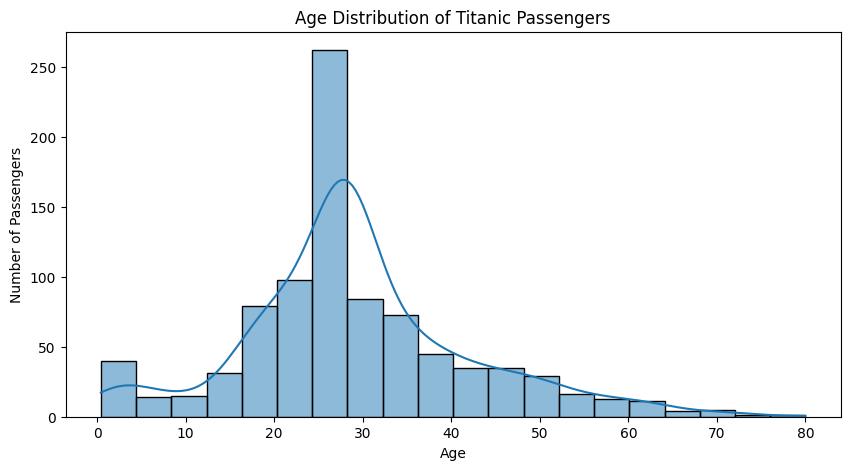

In [12]:

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()


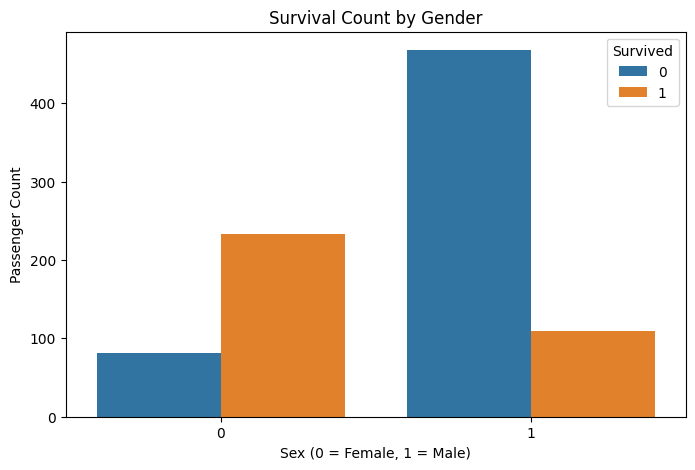

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival Count by Gender")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Passenger Count")

plt.show()

In [14]:
df.to_csv("cleaned_titanic.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [15]:
from google.colab import files

files.download("cleaned_titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

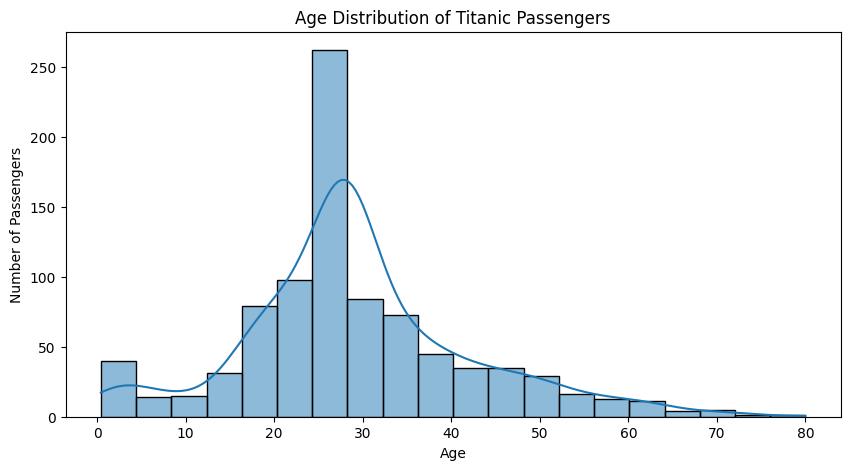

In [16]:

# Age Distribution Visualization

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()


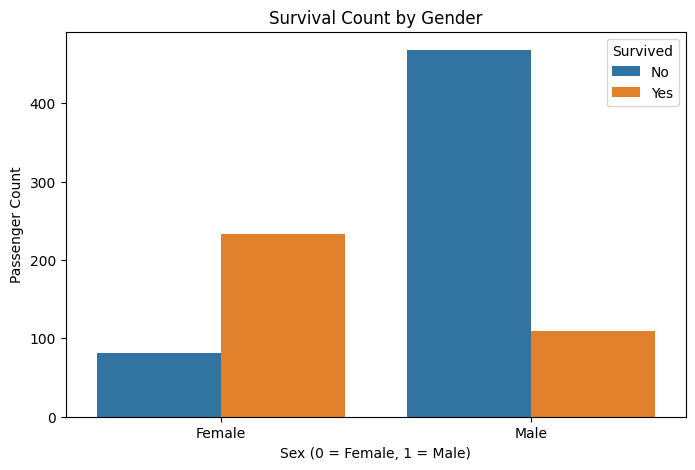

In [17]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival Count by Gender")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Passenger Count")

plt.xticks([0, 1], ["Female", "Male"])

plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()


In [18]:

# Save the cleaned dataset

df.to_csv("cleaned_titanic.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [19]:

print("FINAL PROJECT REPORT")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nFinal Project Status:")
print("Project Completed Successfully!")


FINAL PROJECT REPORT
Total Rows: 891
Total Columns: 13

Total Missing Values:
0

Final Project Status:
Project Completed Successfully!


In [20]:

# Separate input features and target variable

X = df.drop(
    columns=['Survived', 'PassengerId', 'Name', 'Ticket'],
    errors='ignore'
)

y = df['Survived']

print("Input Features:")
print(X.columns.tolist())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Input Features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Features Shape: (891, 9)
Target Shape: (891,)

Target Distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [21]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (712, 9)
Testing Features: (179, 9)
Training Target: (712,)
Testing Target: (179,)


In [22]:

from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

# Predict survival
y_pred_log = log_model.predict(X_test)

print("Logistic Regression Model Trained Successfully!")
print("Total Predictions:", len(y_pred_log))


Logistic Regression Model Trained Successfully!
Total Predictions: 179


In [23]:

from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

# Predict survival
y_pred_log = log_model.predict(X_test)

print("Logistic Regression Model Trained Successfully!")
print("Total Predictions:", len(y_pred_log))


Logistic Regression Model Trained Successfully!
Total Predictions: 179


In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)

print("LOGISTIC REGRESSION - MODEL EVALUATION")
print("--------------------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))


LOGISTIC REGRESSION - MODEL EVALUATION
--------------------------------------
Accuracy : 80.45 %
Precision: 0.7931
Recall   : 0.6667
F1 Score : 0.7244

Confusion Matrix:
[[98 12]
 [23 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [25]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")
print("Total Predictions:", len(y_pred_rf))


Random Forest Model Trained Successfully!
Total Predictions: 179


In [26]:

# Evaluate Random Forest model

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("RANDOM FOREST - MODEL EVALUATION")
print("--------------------------------")
print("Accuracy :", round(accuracy_rf * 100, 2), "%")
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


RANDOM FOREST - MODEL EVALUATION
--------------------------------
Accuracy : 82.12 %
Precision: 0.8033
Recall   : 0.7101
F1 Score : 0.7538

Confusion Matrix:
[[98 12]
 [20 49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       110
           1       0.80      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8045     0.7931  0.6667    0.7244
1        Random Forest    0.8212     0.8033  0.7101    0.7538


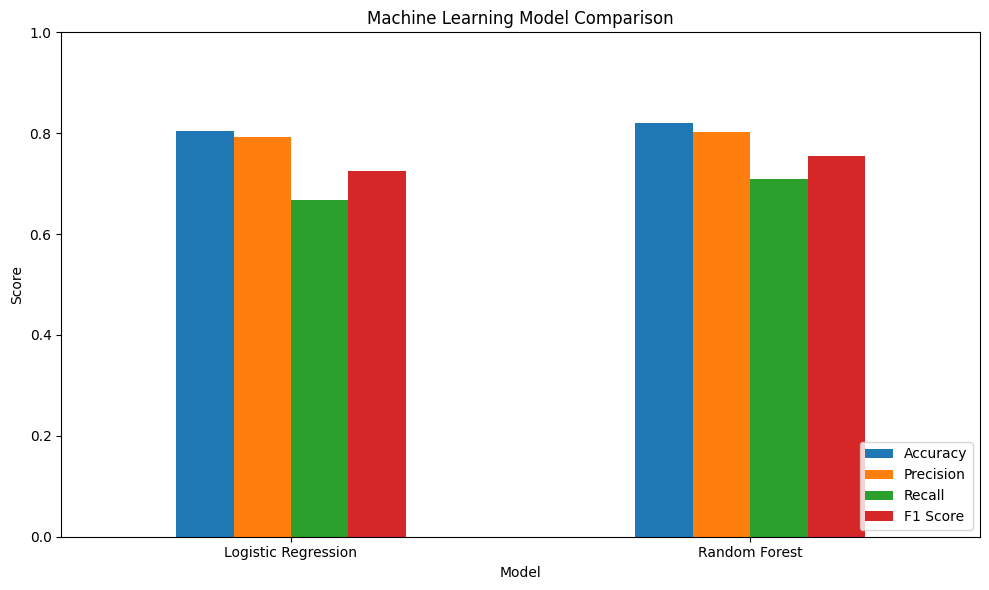

In [27]:

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy, accuracy_rf],
    'Precision': [precision, precision_rf],
    'Recall': [recall, recall_rf],
    'F1 Score': [f1, f1_rf]
})

print(comparison.round(4))

comparison.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


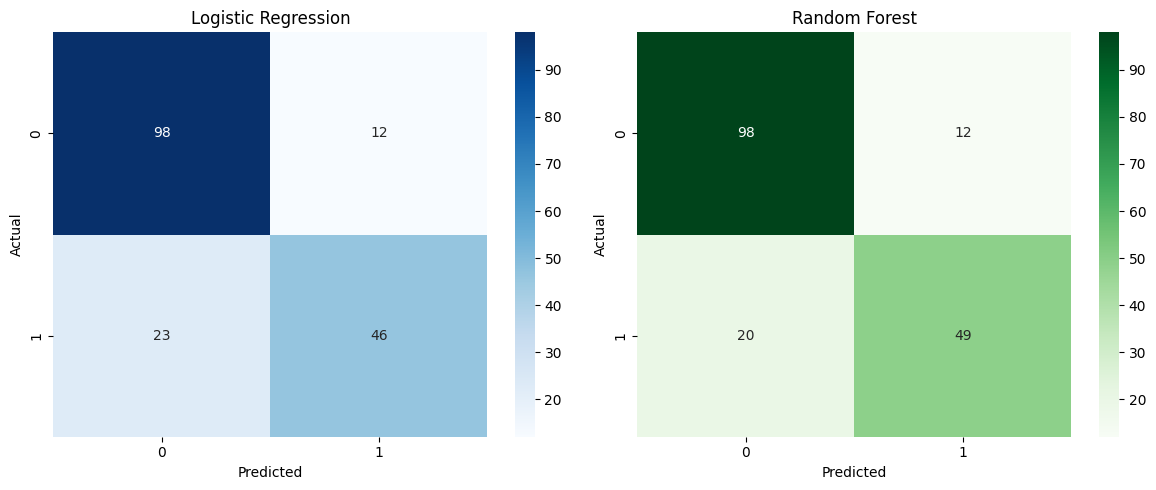

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, y_pred_log),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Random Forest
sns.heatmap(
    confusion_matrix(y_test, y_pred_rf),
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()


In [29]:

# Create sample passenger data

new_passenger = pd.DataFrame([{
    'Pclass': 3,
    'Sex': 0,       # Female = 0, Male = 1
    'Age': 25,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 7.25,
    'Embarked_C': 0,
    'Embarked_Q': 0,
    'Embarked_S': 1
}])

# Predict survival
prediction = rf_model.predict(new_passenger)

# Display result
if prediction[0] == 1:
    print("Prediction: Passenger may have Survived")
else:
    print("Prediction: Passenger may not have Survived")


Prediction: Passenger may have Survived


In [30]:

# Calculate survival probability
probability = rf_model.predict_proba(new_passenger)

print("Survival Probability:",
      round(probability[0][1] * 100, 2), "%")

print("Non-Survival Probability:",
      round(probability[0][0] * 100, 2), "%")


Survival Probability: 77.0 %
Non-Survival Probability: 23.0 %


FEATURE IMPORTANCE
      Feature  Importance
1         Sex    0.274332
5        Fare    0.262774
2         Age    0.241860
0      Pclass    0.093244
3       SibSp    0.051463
4       Parch    0.039707
8  Embarked_S    0.016552
6  Embarked_C    0.012115
7  Embarked_Q    0.007951


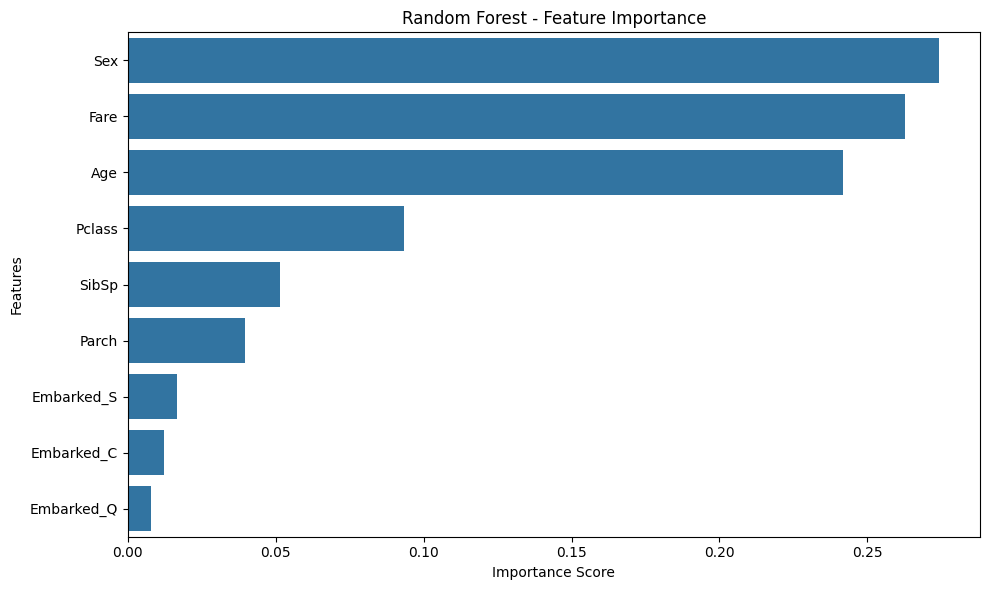

In [31]:

# Get feature importance from Random Forest

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("FEATURE IMPORTANCE")
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


In [32]:

# Reload the original Titanic dataset
raw_df = pd.read_csv('train.csv')

# Remove columns not needed for prediction
raw_df = raw_df.drop(
    columns=['PassengerId', 'Name', 'Ticket', 'Cabin']
)

# Separate features and target
X_raw = raw_df.drop(columns=['Survived'])
y_raw = raw_df['Survived']

print("Original dataset reloaded:", raw_df.shape)
print("\nMissing values:")
print(X_raw.isnull().sum())


Original dataset reloaded: (891, 8)

Missing values:
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [33]:

from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

print("Training data:", X_train_raw.shape)
print("Testing data:", X_test_raw.shape)

print("\nTraining missing values:")
print(X_train_raw.isnull().sum())


Training data: (712, 7)
Testing data: (179, 7)

Training missing values:
Pclass        0
Sex           0
Age         137
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [34]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define numerical and categorical columns
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train_raw)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test_raw)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
print("Remaining missing values:",
      X_train_processed.shape[0] - X_train_processed.shape[0])


Training data after preprocessing: (712, 12)
Testing data after preprocessing: (179, 12)
Remaining missing values: 0


In [35]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Train Logistic Regression
log_model_clean = LogisticRegression(max_iter=1000)
log_model_clean.fit(X_train_processed, y_train_raw)

y_pred_log_clean = log_model_clean.predict(X_test_processed)

# Train Random Forest
rf_model_clean = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model_clean.fit(X_train_processed, y_train_raw)

y_pred_rf_clean = rf_model_clean.predict(X_test_processed)

print("Both models retrained successfully!")
print("Logistic Regression predictions:", len(y_pred_log_clean))
print("Random Forest predictions:", len(y_pred_rf_clean))


Both models retrained successfully!
Logistic Regression predictions: 179
Random Forest predictions: 179


In [36]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Logistic Regression metrics
log_accuracy = accuracy_score(y_test_raw, y_pred_log_clean)
log_precision = precision_score(y_test_raw, y_pred_log_clean)
log_recall = recall_score(y_test_raw, y_pred_log_clean)
log_f1 = f1_score(y_test_raw, y_pred_log_clean)

# Random Forest metrics
rf_accuracy = accuracy_score(y_test_raw, y_pred_rf_clean)
rf_precision = precision_score(y_test_raw, y_pred_rf_clean)
rf_recall = recall_score(y_test_raw, y_pred_rf_clean)
rf_f1 = f1_score(y_test_raw, y_pred_rf_clean)

# Comparison table
final_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [log_accuracy, rf_accuracy],
    'Precision': [log_precision, rf_precision],
    'Recall': [log_recall, rf_recall],
    'F1 Score': [log_f1, rf_f1]
})

print("FINAL MODEL COMPARISON")
print(final_comparison.round(4).to_string(index=False))


FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.8045     0.7931  0.6667    0.7244
      Random Forest    0.7933     0.7667  0.6667    0.7132


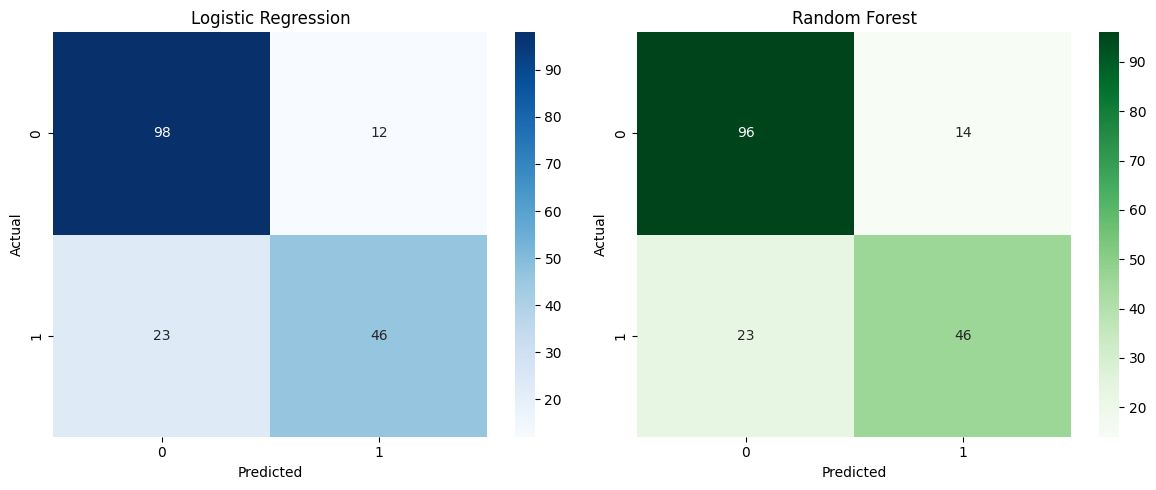

In [37]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test_raw, y_pred_log_clean),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Random Forest
sns.heatmap(
    confusion_matrix(y_test_raw, y_pred_rf_clean),
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()


CORRECTED FEATURE IMPORTANCE
        Feature  Importance
      num__Fare    0.250398
       num__Age    0.246040
  cat__Sex_male    0.157727
cat__Sex_female    0.124618
     num__SibSp    0.047323
  cat__Pclass_3    0.046408
     num__Parch    0.038750
  cat__Pclass_1    0.034596
  cat__Pclass_2    0.017260
cat__Embarked_S    0.017207
cat__Embarked_C    0.012860
cat__Embarked_Q    0.006813


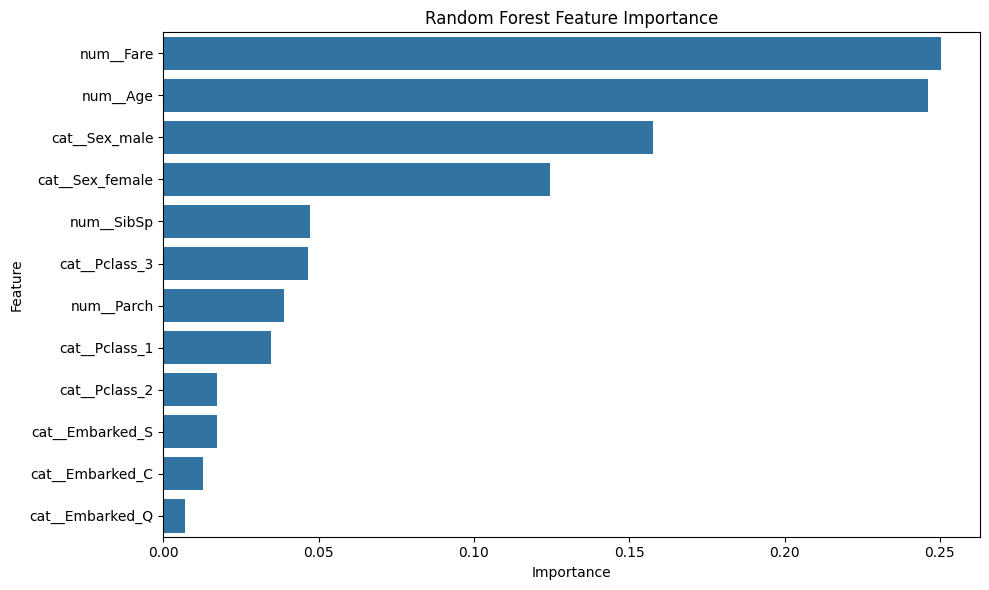

In [38]:

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create feature importance table
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model_clean.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("CORRECTED FEATURE IMPORTANCE")
print(importance_df.to_string(index=False))

# Visualize
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()


In [39]:

# Create new passenger using original dataset format
new_passenger_raw = pd.DataFrame([{
    'Pclass': 3,
    'Sex': 'female',
    'Age': 25,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 7.25,
    'Embarked': 'S'
}])

# Apply the fitted preprocessing pipeline
new_passenger_processed = preprocessor.transform(
    new_passenger_raw
)

# Predict using the best model
prediction = log_model_clean.predict(
    new_passenger_processed
)

probability = log_model_clean.predict_proba(
    new_passenger_processed
)

print("FINAL PASSENGER PREDICTION")

if prediction[0] == 1:
    print("Prediction: Survived")
else:
    print("Prediction: Not Survived")

print("Survival Probability:",
      round(probability[0][1] * 100, 2), "%")

print("Non-Survival Probability:",
      round(probability[0][0] * 100, 2), "%")


FINAL PASSENGER PREDICTION
Prediction: Survived
Survival Probability: 59.77 %
Non-Survival Probability: 40.23 %


In [40]:

import joblib
from sklearn.pipeline import Pipeline

# Combine preprocessing and trained model
final_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', log_model_clean)
])

# Save the complete pipeline
joblib.dump(
    final_model_pipeline,
    'titanic_survival_model.pkl'
)

print("Final model saved successfully!")

# Verify saved model
loaded_model = joblib.load('titanic_survival_model.pkl')

print("Model loaded successfully!")


Final model saved successfully!
Model loaded successfully!


In [41]:

# Predict using the loaded model
loaded_prediction = loaded_model.predict(new_passenger_raw)

loaded_probability = loaded_model.predict_proba(new_passenger_raw)

print("SAVED MODEL VERIFICATION")

print("Prediction:",
      "Survived" if loaded_prediction[0] == 1
      else "Not Survived")

print("Survival Probability:",
      round(loaded_probability[0][1] * 100, 2), "%")

print("Model verification completed!")


SAVED MODEL VERIFICATION
Prediction: Survived
Survival Probability: 59.77 %
Model verification completed!
